In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 12 — Latensi dan kebijakan adaptif

**Tujuan:** kurva performa per jendela dan kebijakan penandaan dini adaptif pada tahap pengembangan.
Hasil ini simulasi atas data arsip, bukan sistem real-time. Waktu dihitung dari awal jam.

In [3]:
import json

import numpy as np
import pandas as pd

from ghremoval.analysis import aurt_delta_bootstrap, checkpoint_scores, latency_table, policy_results, policy_sensitivity
from ghremoval.config import load_context
from ghremoval.models.fit import load_stage
from ghremoval.policy import amoc_curve, first_cross, q_grid, thresholds
from ghremoval.quality import Checks
from ghremoval.report import save_table
from ghremoval.runlog import RunLog
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("12_latency_and_adaptive_policy", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
best = json.loads((ctx.paths.results / "best_params.json").read_text())
cfg = ctx.p.locked["policy"]
windows = ctx.p.locked["windows_minutes"]
primary = cfg["primary_target_precision"]

## 1. Kurva latensi

,cohort,window,n,n_pos,ap_all,ap_5-19,ap_20+
1,fixed,5,22095,560,0.060677,0.043979,0.237695
3,fixed,10,22095,560,0.066426,0.046585,0.261520
5,fixed,15,22095,560,0.071509,0.053531,0.284276
7,fixed,30,22095,560,0.114182,0.087530,0.368441
9,fixed,60,22095,560,0.199826,0.181191,0.413233
11,deployable,5,3544,112,0.138629,0.091391,0.207481
13,deployable,10,8140,230,0.127085,0.080761,0.297719
15,deployable,15,12806,333,0.143044,0.071379,0.415924
17,deployable,30,27579,672,0.151128,0.112452,0.431691
19,deployable,60,56234,1258,0.213086,0.199994,0.406562


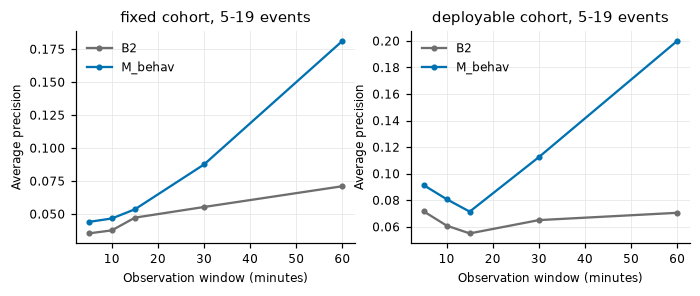

In [4]:
latency = pd.DataFrame(latency_table(ctx, "dev", best))
save_table(latency, "tab_latency_dev", "Average precision by observation window, development stage")
fig, axes = new_figure(width=7.2, height=2.5, ncols=2, sharey=False)
for ax, cohort in zip(axes, ("fixed", "deployable")):
    part = latency[latency.cohort == cohort]
    for model, color in (("B2", "#6E6E6E"), ("M_behav", "#0072B2")):
        rows = part[part.model == model]
        ax.plot(rows["window"], rows["ap_5-19"], marker="o", ms=3, color=color, label=model)
    ax.set_xlabel("Observation window (minutes)"); ax.set_title(f"{cohort} cohort, 5-19 events"); ax.set_ylabel("Average precision"); ax.legend()
save_figure(fig, "fig_latency_curves")
latency[latency.model == "M_behav"][["cohort", "window", "n", "n_pos", "ap_all", "ap_5-19", "ap_20+"]]

## 2. Kebijakan adaptif

In [5]:
results, tables, scores_keep = {}, [], {}
data = load_stage(ctx, "dev", 60)
for cohort in ("fixed", "deployable"):
    behav = checkpoint_scores(ctx, "dev", cohort, "M_behav", best["xgb"])
    base = checkpoint_scores(ctx, "dev", cohort, "B2", None)
    scores_keep[cohort] = behav
    train_for_arm = load_stage(ctx, "dev", 60, cohort=cohort).train
    for arm in ("F2_forward_new_accounts", "F3_forward_batch_excluded"):
        adaptive = policy_results(ctx, behav, arm, train_for_arm)
        baseline = policy_results(ctx, base, arm, train_for_arm)
        results[(cohort, arm)] = (adaptive, baseline)
        for r in adaptive["rows"]:
            tables.append({"cohort": cohort, "arm": arm, "model": "M_behav", **r})
        for r in baseline["rows"]:
            if r["policy"] == "adaptive":
                tables.append({"cohort": cohort, "arm": arm, "model": "B2_first_cross", **r})
policy_table = pd.DataFrame(tables)
save_table(policy_table, "tab_policy", "Early-flagging policy comparison, development stage (observed label)")
policy_table[(policy_table.target == primary) & (policy_table.cohort == "fixed") & (policy_table.arm == "F2_forward_new_accounts")][["model", "policy", "status", "q", "kappa", "n_flagged", "precision", "recall", "aurt", "median_time_tp"]]

,model,policy,status,q,kappa,n_flagged,precision,recall,aurt,median_time_tp
6,M_behav,adaptive,ok,0.395,0.0,64,0.390625,0.044643,0.023095,30.0
7,M_behav,fixed_5,ok,0.335,0.0,6,0.333333,0.003571,0.003333,5.0
8,M_behav,fixed_10,ok,0.335,0.0,26,0.346154,0.016071,0.013929,10.0
9,M_behav,fixed_15,ok,0.270,0.0,17,0.588235,0.017857,0.014286,15.0
10,M_behav,fixed_30,ok,0.295,0.0,14,0.785714,0.019643,0.011786,30.0
11,M_behav,fixed_60,ok,0.395,0.0,33,0.424242,0.025000,0.005000,60.0
19,B2_first_cross,adaptive,ok,0.545,0.0,15,0.133333,0.003571,0.001786,37.5


## 3. Adaptif terhadap jendela tetap terbaik

In [6]:
comparisons = {}
for (cohort, arm), (adaptive, _baseline) in results.items():
    if ("adaptive", primary) in adaptive["times"] and ("best_fixed", primary) in adaptive["times"]:
        comparisons[f"{cohort}|{arm}"] = {"best_fixed_window": adaptive["best_fixed"].get(primary), **aurt_delta_bootstrap(ctx, scores_keep[cohort], adaptive["times"][("adaptive", primary)], adaptive["times"][("best_fixed", primary)], adaptive["mask"])}
    else:
        comparisons[f"{cohort}|{arm}"] = {"status": "target precision tidak tercapai"}
comparison_table = pd.DataFrame(comparisons).T.reset_index(names="setting")
(ctx.paths.results / "policy_dev.json").write_text(json.dumps(comparisons, indent=2, default=float) + "\n")
comparison_table

,setting,best_fixed_window,delta,low,high,p_one_sided,n_reps
0,fixed|F2_forward_new_accounts,15.0,0.008810,0.003817,0.014748,0.0,2000.0
1,fixed|F3_forward_batch_excluded,15.0,0.005859,0.001433,0.011728,0.0,2000.0
2,deployable|F2_forward_new_accounts,30.0,0.009380,0.005142,0.013762,0.0,2000.0
3,deployable|F3_forward_batch_excluded,30.0,0.010686,0.004649,0.016750,0.0,2000.0


## 3b. Sensitivitas

Horizon lain dan perbandingan pada precision teramati yang disamakan. Precision yang tercapai bisa berbeda antarkebijakan walaupun targetnya sama.
Pada perbandingan yang disamakan, `q` dipilih memakai label evaluasi untuk kedua kebijakan, jadi hasilnya bukan kinerja yang bisa dicapai saat dipakai.

In [7]:
sensitivity = pd.DataFrame([{"cohort": cohort, "arm": arm, **row} for (cohort, arm), (adaptive, _baseline) in results.items() for row in policy_sensitivity(ctx, scores_keep[cohort], adaptive, primary)])
save_table(sensitivity, "tab_policy_sensitivity", "Policy sensitivity, development stage: other horizons and matched observed precision (exploratory, observed label)")
sensitivity

,cohort,arm,analysis,target,status,horizon,aurt_adaptive,aurt_best_fixed,delta,level,policy,window,q,n_flagged,precision,recall,aurt,median_time_tp
0,fixed,F2_forward_new_accounts,horizon,0.7,ok,65.0,0.019780,0.013736,0.006044,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,fixed,F2_forward_new_accounts,horizon,0.7,ok,90.0,0.026687,0.014881,0.011806,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.5,adaptive,NaN,0.670,41.0,0.512195,0.037500,0.019286,30.0
3,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.5,best_fixed,15.0,0.270,17.0,0.588235,0.017857,0.014286,15.0
4,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.7,adaptive,NaN,0.795,11.0,0.818182,0.016071,0.012738,10.0
5,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.7,best_fixed,30.0,0.295,14.0,0.785714,0.019643,0.011786,30.0
6,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.9,adaptive,NaN,0.945,8.0,1.000000,0.014286,0.011667,10.0
7,fixed,F2_forward_new_accounts,matched_precision,0.7,ok,NaN,NaN,NaN,NaN,0.9,best_fixed,10.0,0.670,6.0,1.000000,0.010714,0.009286,10.0
8,fixed,F3_forward_batch_excluded,horizon,0.7,ok,65.0,0.018820,0.014617,0.004202,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,fixed,F3_forward_batch_excluded,horizon,0.7,ok,90.0,0.023489,0.015835,0.007654,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Kurva recall terhadap waktu dan AMOC

[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_amoc.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_amoc.png')]

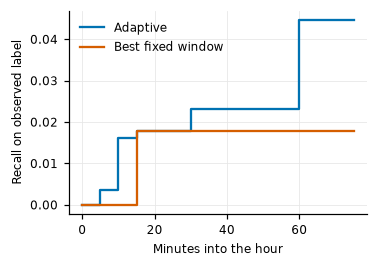

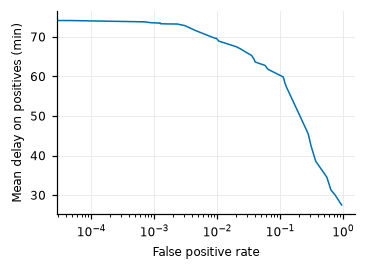

In [8]:
behav = scores_keep["fixed"]
adaptive = results[("fixed", "F2_forward_new_accounts")][0]
horizon = cfg["aurt_horizon_minutes"]
mask = adaptive["mask"]
y = behav["test_y"]
points = np.arange(0, horizon + 1)
fig, ax = new_figure()
if ("adaptive", primary) in adaptive["times"]:
    for key, color, label in ((("adaptive", primary), "#0072B2", "Adaptive"), (("best_fixed", primary), "#D55E00", "Best fixed window")):
        t = adaptive["times"][key][mask]
        ax.step(points, [((t <= p) & np.isfinite(t) & (y[mask] == 1)).sum() / max(y[mask].sum(), 1) for p in points], where="post", color=color, label=label)
    ax.set_xlabel("Minutes into the hour"); ax.set_ylabel("Recall on observed label"); ax.legend()
save_figure(fig, "fig_recall_time")
curve = pd.DataFrame(amoc_curve({c: v[mask] for c, v in behav["test_prob"].items()}, y[mask], 0.0, q_grid(cfg["q_grid_size"]), horizon))
fig, ax = new_figure()
ax.plot(curve["false_positive_rate"], curve["mean_delay_positive"], color="#0072B2", lw=1)
ax.set_xscale("log"); ax.set_xlabel("False positive rate"); ax.set_ylabel("Mean delay on positives (min)")
save_figure(fig, "fig_amoc")

## Ringkasan & cek

In [9]:
valid_checkpoints = set(windows)
all_times = np.concatenate([t[np.isfinite(t)] for (_, arm), (a, _b) in results.items() for t in a["times"].values() if len(t)])
checks.add("Q18", set(np.unique(all_times)).issubset(valid_checkpoints), "waktu penandaan selalu checkpoint yang valid")
checks.add("Q17", set(data.test["week"].unique()) == {"w2"}, "evaluasi pengembangan pada w2")
checks.raise_if_failed()
print(run.finish(n_settings=len(results)))

[LULUS] Q18: waktu penandaan selalu checkpoint yang valid
[LULUS] Q17: evaluasi pengembangan pada w2
{'notebook': '12_latency_and_adaptive_policy', 'finished_at_utc': '2026-11-10T12:08:41+00:00', 'git_commit': 'f04dbd3', 'duration_seconds': 115.0, 'counts': {'n_settings': 4}}
